In [1]:
### RBF Network

In [3]:
import numpy as np
from scipy.spatial.distance import cdist
from sklearn.cluster import KMeans
from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt

In [5]:
# Generate sample data
np.random.seed(0)

X = np.random.rand(100, 2)

y = np.sin(X[:, 0]) + np.cos(X[:, 1])

print("Input Data Shape:", X.shape)
print("Output Data Shape:", y.shape)

print("\nFirst 5 Input Samples:")
print(X[:5])

print("\nFirst 5 Output Samples:")
print(y[:5])

Input Data Shape: (100, 2)
Output Data Shape: (100,)

First 5 Input Samples:
[[0.5488135  0.71518937]
 [0.60276338 0.54488318]
 [0.4236548  0.64589411]
 [0.43758721 0.891773  ]
 [0.96366276 0.38344152]]

First 5 Output Samples:
[1.27664442 1.42210887 1.20965679 1.05178854 1.74866934]


In [7]:
# Define the Gaussian Radial Basis Function

def rbf(x, c, s):
    return np.exp(-np.linalg.norm(x - c)**2 / (2 * s**2))

In [9]:
# Choose centers using K-Means clustering

kmeans = KMeans(n_clusters=10, random_state=0, n_init=10)

kmeans.fit(X)

centers = kmeans.cluster_centers_

print("RBF Centers:")
print(centers)

print("\nNumber of Centers:", len(centers))

C:\Users\deepa\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


RBF Centers:
[[0.81729792 0.89206532]
 [0.18236966 0.3591488 ]
 [0.72525974 0.08717812]
 [0.15136214 0.88553259]
 [0.54600585 0.61587283]
 [0.62234101 0.33365079]
 [0.87294367 0.54855028]
 [0.15343985 0.64337019]
 [0.4673428  0.88480119]
 [0.25230191 0.12073884]]

Number of Centers: 10


In [11]:
# Calculate the spread parameter

d_max = np.max(cdist(centers, centers, 'euclidean'))

sigma = d_max / np.sqrt(2 * len(centers))

print("Maximum Distance:", d_max)
print("Sigma:", sigma)

Maximum Distance: 0.9832234376921759
Sigma: 0.21985544437507343


In [13]:
# Compute the RBF hidden layer output

R = np.zeros((X.shape[0], len(centers)))

for i in range(X.shape[0]):
    for j in range(len(centers)):
        R[i, j] = rbf(X[i], centers[j], sigma)

print("RBF Layer Output Shape:", R.shape)

print("\nFirst 5 Rows:")
print(R[:5])

RBF Layer Output Shape: (100, 10)

First 5 Rows:
[[3.43260335e-01 6.71851277e-02 1.22556500e-02 1.44540139e-01
  9.02926545e-01 2.09770434e-01 2.53091311e-01 1.88179523e-01
  6.93335033e-01 1.04121335e-02]
 [1.78542281e-01 1.12480062e-01 9.80519068e-02 3.65849771e-02
  9.18096643e-01 6.27813306e-01 4.69899532e-01 1.12058283e-01
  2.50346820e-01 4.36564766e-02]
 [1.07556516e-01 2.33926262e-01 1.54517180e-02 2.56409100e-01
  8.48595300e-01 2.42473615e-01 1.12354272e-01 4.69842900e-01
  5.43267662e-01 4.25735785e-02]
 [2.25051663e-01 2.70978867e-02 5.24759361e-04 4.28336309e-01
  4.02927366e-01 2.80070269e-02 4.16211703e-02 2.29131012e-01
  9.90385056e-01 1.49644319e-03]
 [5.51544991e-02 1.79925951e-03 2.24058200e-01 8.00280305e-05
  9.41143083e-02 2.92074748e-01 6.92724178e-01 5.58963385e-04
  5.80961606e-03 2.61005973e-03]]


In [15]:
# Calculate output weights using pseudo-inverse

W = np.dot(np.linalg.pinv(R), y)

print("Output Weights:")
print(W)

Output Weights:
[ 0.80590659  0.61019212  1.72735391  0.41582228  0.32201967 -0.19524446
  1.32765142  0.32566277  0.40802836  0.78065081]


In [17]:
# Define RBF Network prediction function

def rbf_network(X, centers, sigma, W):

    R = np.zeros((X.shape[0], len(centers)))

    for i in range(X.shape[0]):
        for j in range(len(centers)):
            R[i, j] = rbf(X[i], centers[j], sigma)

    return np.dot(R, W)

In [19]:
# Make predictions

y_pred = rbf_network(X, centers, sigma, W)

print("Actual Values:")
print(y[:10])

print("\nPredicted Values:")
print(y_pred[:10])

Actual Values:
[1.27664442 1.42210887 1.20965679 1.05178854 1.74866934 1.57493157
 1.13934273 1.06718297 0.6931572  1.3467851 ]

Predicted Values:
[1.33703675 1.36675922 1.14573578 1.03635732 1.33017535 1.78008571
 1.1084286  0.83000636 0.6359322  1.4559836 ]


In [21]:
# Calculate Mean Squared Error

mse = mean_squared_error(y, y_pred)

print("Mean Squared Error:", mse)

Mean Squared Error: 0.0238750147421838


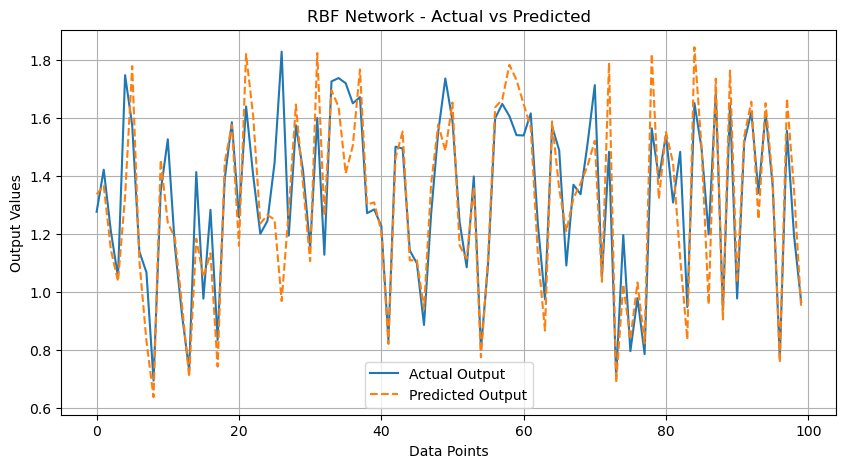

In [23]:
# Plot actual and predicted values

plt.figure(figsize=(10, 5))

plt.plot(y, label="Actual Output")
plt.plot(y_pred, label="Predicted Output", linestyle="--")

plt.xlabel("Data Points")
plt.ylabel("Output Values")
plt.title("RBF Network - Actual vs Predicted")

plt.legend()
plt.grid(True)
plt.show()